# Dual 10x10 Gridworld with Adjacency Matrix

This notebook creates a dual-gridworld system with:
- First 10x10 grid with agent (🤖) and intermediate goal (⭐)
- Second 10x10 grid accessible through intermediate goal, containing final goal (🎯)
- Adjacency matrix representation with 4-directional connectivity
- Semi-permeable door at intermediate goal connecting the two grids
- Self-absorbing final goal state

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.patches as patches
import seaborn as sns
from scipy.sparse import csr_matrix

## Configuration

**Change these coordinates to move the elements around the gridworld:**

In [ ]:
# Grid configuration
GRID_SIZE = 10
TOTAL_STATES = 2 * GRID_SIZE * GRID_SIZE  # Two 10x10 grids = 200 states

# Positions (row, column) - coordinates are (0,0) to (9,9)
AGENT_POS = (0, 0)                    # Starting position of agent (Grid 1)
INTERMEDIATE_GOAL_POS = (4, 5)        # Semi-permeable door (Grid 1)
GOAL_POS = (9, 9)                     # Final goal position (Grid 2)

# State indexing: Grid 1 = states 0-99, Grid 2 = states 100-199
# State index = grid_id * 100 + row * 10 + col

# Colors and symbols
AGENT_COLOR = '#4CAF50'      # Green
GOAL_COLOR = '#F44336'       # Red
INTERMEDIATE_COLOR = '#FF9800'  # Orange
GRID_COLOR = '#E0E0E0'       # Light gray

## State Indexing Functions

In [ ]:
def pos_to_state(row, col, grid_id=0):
    """Convert (row, col, grid_id) to state index."""
    return grid_id * (GRID_SIZE * GRID_SIZE) + row * GRID_SIZE + col

def state_to_pos(state):
    """Convert state index to (row, col, grid_id)."""
    grid_id = state // (GRID_SIZE * GRID_SIZE)
    remaining = state % (GRID_SIZE * GRID_SIZE)
    row = remaining // GRID_SIZE
    col = remaining % GRID_SIZE
    return row, col, grid_id

def get_valid_neighbors(row, col):
    """Get valid 4-directional neighbors within grid bounds."""
    neighbors = []
    # North, South, East, West
    directions = [(-1, 0), (1, 0), (0, 1), (0, -1)]
    
    for dr, dc in directions:
        new_row, new_col = row + dr, col + dc
        if 0 <= new_row < GRID_SIZE and 0 <= new_col < GRID_SIZE:
            neighbors.append((new_row, new_col))
    
    return neighbors

## Adjacency Matrix Generation

In [ ]:
def create_adjacency_matrix():
    """
    Create adjacency matrix for dual gridworld system.
    
    Rules:
    1. Each grid cell connects bilaterally to N,S,E,W neighbors
    2. Intermediate goal is semi-permeable door between grids
    3. Final goal is self-absorbing state
    
    Returns:
        adjacency_matrix: 200x200 sparse matrix
        state_info: dictionary with state information
    """
    # Initialize adjacency matrix
    adj_matrix = np.zeros((TOTAL_STATES, TOTAL_STATES))
    
    # Grid 1: Standard 4-directional connectivity
    for row in range(GRID_SIZE):
        for col in range(GRID_SIZE):
            current_state = pos_to_state(row, col, grid_id=0)
            neighbors = get_valid_neighbors(row, col)
            
            for neighbor_row, neighbor_col in neighbors:
                neighbor_state = pos_to_state(neighbor_row, neighbor_col, grid_id=0)
                adj_matrix[current_state, neighbor_state] = 1
    
    # Grid 2: Standard 4-directional connectivity
    for row in range(GRID_SIZE):
        for col in range(GRID_SIZE):
            current_state = pos_to_state(row, col, grid_id=1)
            neighbors = get_valid_neighbors(row, col)
            
            for neighbor_row, neighbor_col in neighbors:
                neighbor_state = pos_to_state(neighbor_row, neighbor_col, grid_id=1)
                adj_matrix[current_state, neighbor_state] = 1
    
    # Semi-permeable door: Intermediate goal connects grids
    intermediate_state_grid1 = pos_to_state(INTERMEDIATE_GOAL_POS[0], INTERMEDIATE_GOAL_POS[1], grid_id=0)
    intermediate_state_grid2 = pos_to_state(INTERMEDIATE_GOAL_POS[0], INTERMEDIATE_GOAL_POS[1], grid_id=1)
    
    # Bidirectional connection between grids at intermediate goal
    adj_matrix[intermediate_state_grid1, intermediate_state_grid2] = 1
    adj_matrix[intermediate_state_grid2, intermediate_state_grid1] = 1
    
    # Self-absorbing final goal state
    goal_state = pos_to_state(GOAL_POS[0], GOAL_POS[1], grid_id=1)
    adj_matrix[goal_state, goal_state] = 1
    # Remove all outgoing connections from goal state (except self-loop)
    adj_matrix[goal_state, :] = 0
    adj_matrix[goal_state, goal_state] = 1
    
    # Create state info dictionary
    state_info = {
        'agent_state': pos_to_state(AGENT_POS[0], AGENT_POS[1], grid_id=0),
        'intermediate_state_g1': intermediate_state_grid1,
        'intermediate_state_g2': intermediate_state_grid2,
        'goal_state': goal_state,
        'total_states': TOTAL_STATES,
        'grid_size': GRID_SIZE
    }
    
    return csr_matrix(adj_matrix), state_info

## Visualization Functions

In [ ]:
def visualize_single_gridworld():
    """Visualize single gridworld with both intermediate and final goals."""
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    
    # Create the grid
    for i in range(GRID_SIZE + 1):
        ax.axhline(i, color=GRID_COLOR, linewidth=1)
        ax.axvline(i, color=GRID_COLOR, linewidth=1)
    
    # Add agent
    agent_rect = Rectangle(
        (AGENT_POS[1], GRID_SIZE - 1 - AGENT_POS[0]), 
        1, 1, facecolor=AGENT_COLOR, alpha=0.7, edgecolor='black', linewidth=2
    )
    ax.add_patch(agent_rect)
    ax.text(AGENT_POS[1] + 0.5, GRID_SIZE - 1 - AGENT_POS[0] + 0.5, '🤖', 
             fontsize=20, ha='center', va='center')
    
    # Add intermediate goal (semi-permeable door)
    intermediate_rect = Rectangle(
        (INTERMEDIATE_GOAL_POS[1], GRID_SIZE - 1 - INTERMEDIATE_GOAL_POS[0]), 
        1, 1, facecolor=INTERMEDIATE_COLOR, alpha=0.7, edgecolor='black', linewidth=2
    )
    ax.add_patch(intermediate_rect)
    ax.text(INTERMEDIATE_GOAL_POS[1] + 0.5, GRID_SIZE - 1 - INTERMEDIATE_GOAL_POS[0] + 0.5, '⭐', 
             fontsize=20, ha='center', va='center')
    
    # Add final goal
    goal_rect = Rectangle(
        (GOAL_POS[1], GRID_SIZE - 1 - GOAL_POS[0]), 
        1, 1, facecolor=GOAL_COLOR, alpha=0.7, edgecolor='black', linewidth=2
    )
    ax.add_patch(goal_rect)
    ax.text(GOAL_POS[1] + 0.5, GRID_SIZE - 1 - GOAL_POS[0] + 0.5, '🎯', 
             fontsize=20, ha='center', va='center')
    
    # Set up the plot
    ax.set_xlim(0, GRID_SIZE)
    ax.set_ylim(0, GRID_SIZE)
    ax.set_aspect('equal')
    ax.set_title('10x10 Gridworld (200 States: 2 layers)', fontsize=16, fontweight='bold')
    ax.set_xlabel('Column')
    ax.set_ylabel('Row (flipped)')
    
    # Set ticks
    ax.set_xticks(range(GRID_SIZE + 1))
    ax.set_yticks(range(GRID_SIZE + 1))
    
    # Add legend
    legend_elements = [
        patches.Patch(color=AGENT_COLOR, label='Agent 🤖 (Start)'),
        patches.Patch(color=INTERMEDIATE_COLOR, label='Semi-permeable Door ⭐ (Between Layers)'),
        patches.Patch(color=GOAL_COLOR, label='Final Goal 🎯 (Layer 2, Absorbing)')
    ]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1))
    
    # Add state space info
    info_text = (f"State Space: 200 total states\n"
                f"Layer 1: States 0-99\n"
                f"Layer 2: States 100-199\n\n"
                f"Agent: State {pos_to_state(AGENT_POS[0], AGENT_POS[1], 0)}\n"
                f"Door: States {pos_to_state(INTERMEDIATE_GOAL_POS[0], INTERMEDIATE_GOAL_POS[1], 0)}"
                f" ↔ {pos_to_state(INTERMEDIATE_GOAL_POS[0], INTERMEDIATE_GOAL_POS[1], 1)}\n"
                f"Goal: State {pos_to_state(GOAL_POS[0], GOAL_POS[1], 1)}")
    
    ax.text(
        1.02, 0.5, info_text, 
        transform=ax.transAxes, 
        fontsize=10, 
        verticalalignment='center',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    )
    
    plt.tight_layout()
    plt.show()
    
    return fig, ax

def visualize_adjacency_matrix(adj_matrix, max_states_to_show=50):
    """Visualize a subset of the adjacency matrix."""
    # Show only first max_states_to_show x max_states_to_show for readability
    subset = adj_matrix[:max_states_to_show, :max_states_to_show].toarray()
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(subset, cmap='Blues', cbar=True, square=True, 
                xticklabels=5, yticklabels=5)
    plt.title(f'Adjacency Matrix (First {max_states_to_show}x{max_states_to_show} states)')
    plt.xlabel('To State')
    plt.ylabel('From State')
    plt.show()

## Generate and Display Results

Adjacency Matrix Shape: (200, 200)
Number of connections: 721

Key States:
Agent starting state: 0
Intermediate goal (Grid 1): 45
Intermediate goal (Grid 2): 145
Final goal state: 199


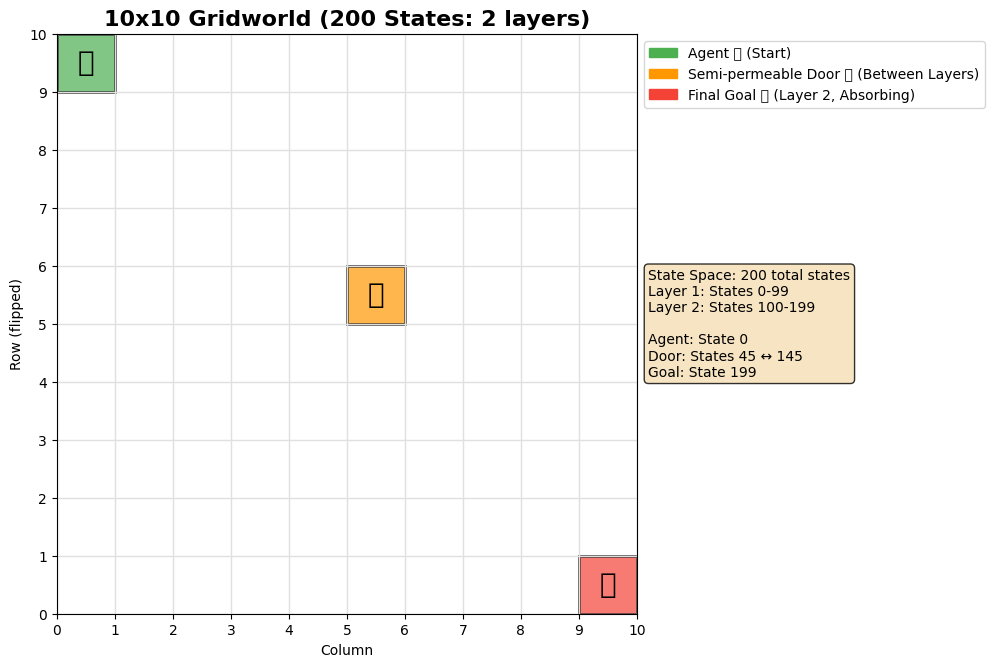

In [ ]:
# Create adjacency matrix
adj_matrix, state_info = create_adjacency_matrix()

# Display information
print(f"Adjacency Matrix Shape: {adj_matrix.shape}")
print(f"Number of connections: {adj_matrix.nnz}")
print(f"\nKey States:")
print(f"Agent starting state: {state_info['agent_state']}")
print(f"Intermediate goal (Grid 1): {state_info['intermediate_state_g1']}")
print(f"Intermediate goal (Grid 2): {state_info['intermediate_state_g2']}")
print(f"Final goal state: {state_info['goal_state']}")

# Visualize the single gridworld with state space info
fig_grid, ax = visualize_single_gridworld()

## Adjacency Matrix Analysis

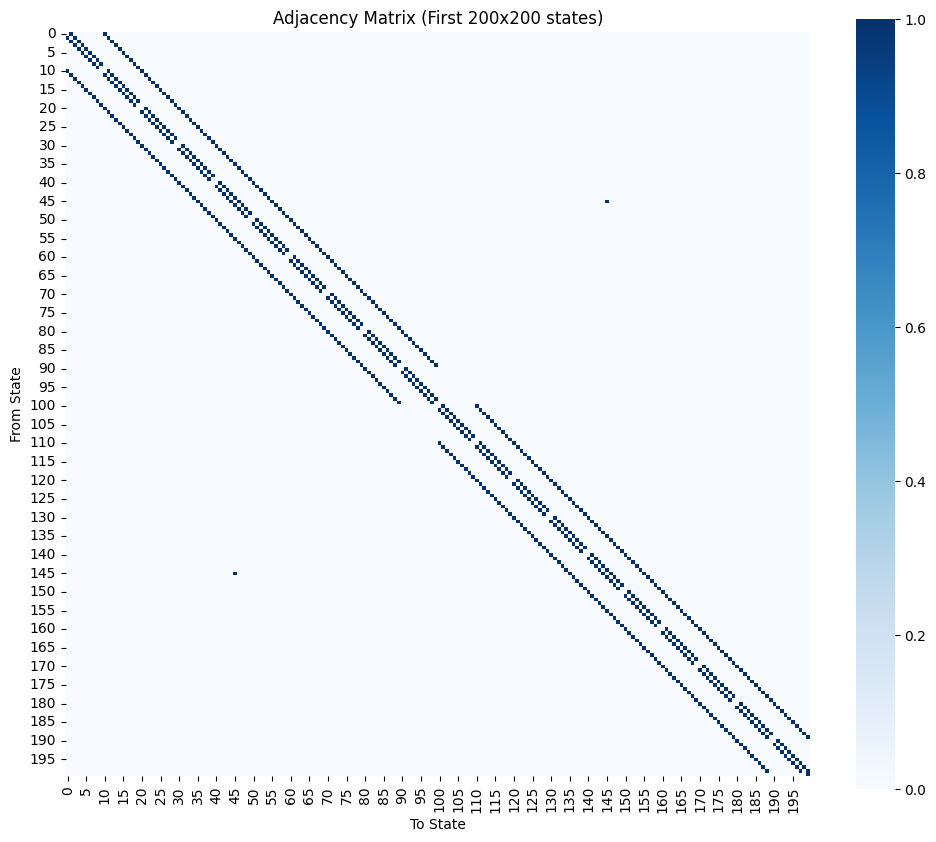


=== Connectivity Analysis ===

Agent state 0 connections:
  Connected to 2 states: [ 1 10]...

Intermediate goal Grid 1 (state 45) connections:
  Connected to 5 states: [ 35  44  46  55 145]

Intermediate goal Grid 2 (state 145) connections:
  Connected to 5 states: [ 45 135 144 146 155]

Goal state 199 connections (should only be self-loop):
  Connected to 1 states: [199]

Bridge between grids exists: True

=== Summary ===
Total states: 200
Total connections: 721
Average connections per state: 3.60
Matrix density: 1.8025%
Goal is properly absorbing: True
Bridge between grids: True


In [ ]:
# Visualize adjacency matrix (first 50x50 subset)
visualize_adjacency_matrix(adj_matrix, max_states_to_show=200)

# Analyze connectivity
def analyze_connectivity(adj_matrix, state_info):
    """Analyze the connectivity properties of the adjacency matrix."""
    print("\n=== Connectivity Analysis ===")
    
    # Check specific connections
    agent_state = state_info['agent_state']
    intermediate_g1 = state_info['intermediate_state_g1']
    intermediate_g2 = state_info['intermediate_state_g2']
    goal_state = state_info['goal_state']
    
    print(f"\nAgent state {agent_state} connections:")
    agent_connections = adj_matrix[agent_state, :].nonzero()[1]
    print(f"  Connected to {len(agent_connections)} states: {agent_connections[:10]}...")
    
    print(f"\nIntermediate goal Grid 1 (state {intermediate_g1}) connections:")
    int_g1_connections = adj_matrix[intermediate_g1, :].nonzero()[1]
    print(f"  Connected to {len(int_g1_connections)} states: {int_g1_connections}")
    
    print(f"\nIntermediate goal Grid 2 (state {intermediate_g2}) connections:")
    int_g2_connections = adj_matrix[intermediate_g2, :].nonzero()[1]
    print(f"  Connected to {len(int_g2_connections)} states: {int_g2_connections}")
    
    print(f"\nGoal state {goal_state} connections (should only be self-loop):")
    goal_connections = adj_matrix[goal_state, :].nonzero()[1]
    print(f"  Connected to {len(goal_connections)} states: {goal_connections}")
    
    # Check bridge between grids
    bridge_exists = adj_matrix[intermediate_g1, intermediate_g2] == 1
    print(f"\nBridge between grids exists: {bridge_exists}")
    
    return {
        'agent_connections': len(agent_connections),
        'bridge_exists': bridge_exists,
        'goal_is_absorbing': len(goal_connections) == 1 and goal_connections[0] == goal_state
    }

# Run analysis
connectivity_stats = analyze_connectivity(adj_matrix, state_info)

print("\n=== Summary ===")
print(f"Total states: {TOTAL_STATES}")
print(f"Total connections: {adj_matrix.nnz}")
print(f"Average connections per state: {adj_matrix.nnz / TOTAL_STATES:.2f}")
print(f"Matrix density: {adj_matrix.nnz / (TOTAL_STATES ** 2) * 100:.4f}%")
print(f"Goal is properly absorbing: {connectivity_stats['goal_is_absorbing']}")
print(f"Bridge between grids: {connectivity_stats['bridge_exists']}")

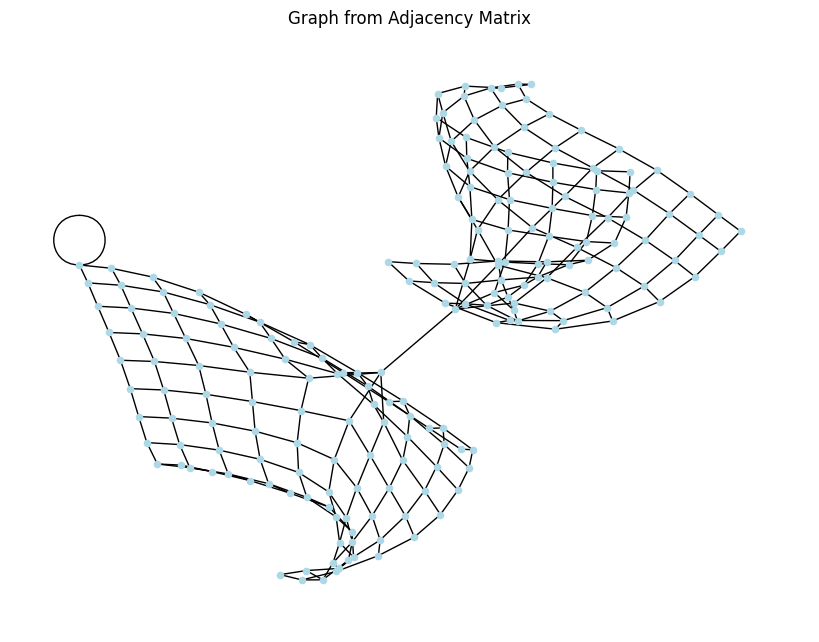

In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# Create graph from adjacency matrix
G = nx.from_numpy_array(adj_matrix)

# Visualize the graph
plt.figure(figsize=(8, 6))
nx.draw(G, with_labels=False, node_color='lightblue', 
        node_size=20, font_size=16, font_weight='bold')
plt.title("Graph from Adjacency Matrix")
plt.show()